# Which NFL Injuries Hurt Teams the Most? 
    Measuring Team EPA Before and During Injury

In [35]:
#Import Libraries 
import matplotlib.pyplot as plt
import nflreadpy as nfl
import numpy as np
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
from IPython.display import display


Load Seasons: 2019-2024

In [2]:
# Load 6 seasons of play-by-play and injury data (2019-2024)
seasons = list(range(2019, 2025)) 
pbp = nfl.load_pbp(seasons).to_pandas()
injuries = nfl.load_injuries(seasons).to_pandas()

print(f"Loaded {len(pbp):,} plays and {len(injuries):,} injury report rows.")

Loaded 293,478 plays and 34,136 injury report rows.


Create Offense and Defensive Position Categories 

In [3]:
# Offensive position categories
offense_position_map = {
    "QB": "Quarterback",
    "RB": "Running Back",
    "FB": "Running Back",
    "WR": "Wide Receiver",
    "TE": "Tight End",
    "T": "Offensive Line",
    "G": "Offensive Line",
    "C": "Offensive Line"
}

# Defensive position categories
defense_position_map = {
    "DE": "Defensive Line",
    "DT": "Defensive Line",
    "LB": "Linebacker",
    "CB": "Cornerback",
    "S": "Safety"
}

Import Injury Data and Explore

In [4]:
#Most common primary injuries
print("\n--- TOP 25 PRIMARY INJURIES ---")
print(injuries["report_primary_injury"].value_counts(dropna=False).head(25))

#Check the game status designations (Out, Doubtful, Questionable, etc.)
print("\n--- GAME STATUS COUNTS ---")
print(injuries["report_status"].value_counts(dropna=False))

#Remove rows where 'report_primary_injury' is NaN / None
injuries_clean = injuries.dropna(subset=["report_primary_injury"]).copy()

#Remove blank strings or "Not Injury Related" entries
injuries_clean = injuries_clean[
    (injuries_clean["report_primary_injury"].str.strip() != "")
    & (~injuries_clean["report_primary_injury"].str.contains(
        "Not Injury Related", case=False, na=False
    ))
].copy()

print("\n--- CLEANED TOP 25 INJURIES ---")
print(injuries_clean["report_primary_injury"].value_counts().head(25))


--- TOP 25 PRIMARY INJURIES ---
report_primary_injury
NaN                                     18211
Knee                                     2642
Ankle                                    2369
Hamstring                                1823
Shoulder                                 1028
Concussion                                943
Groin                                     734
Illness                                   682
Calf                                      670
Foot                                      646
Back                                      574
Hip                                       477
Neck                                      354
Quadricep                                 347
Toe                                       254
Elbow                                     187
Ribs                                      187
Thigh                                     163
Hand                                      134
Abdomen                                   130
Chest                    

In [5]:
#Create Injury Types
#Standardize injury descriptions
injuries_clean["injury_raw"] = (
    injuries_clean["report_primary_injury"]
    .str.lower()
    .str.strip()
)

# Map injury descriptions into broader categories
injury_map = {
    "knee": "Knee",
    "hamstring": "Hamstring",
    "ankle": "Ankle",
    "concussion": "Concussion",
    "shoulder": "Shoulder",
    "groin": "Groin",
    "foot": "Foot",
    "back": "Back",
    "calf": "Calf",
    "quadricep": "Quad",
    "quad": "Quad",
    "hip": "Hip",
    "ribs": "Ribs",
    "rib": "Ribs",
    "chest": "Chest/Pec",
    "pectoral": "Chest/Pec",
    "achilles": "Achilles",
    "neck": "Neck",
    "elbow": "Elbow",
    "hand": "Hand/Wrist",
    "wrist": "Hand/Wrist",
    "thumb": "Hand/Wrist",
    "finger": "Hand/Wrist",
    "toe": "Toe",
    "illness": "Illness"
}

injury_group_map = {
    "Hamstring": "Lower Body",
    "Groin": "Lower Body",
    "Calf": "Lower Body",
    "Quad": "Lower Body",
    "Knee": "Lower Body",
    "Ankle": "Lower Body",
    "Foot": "Lower Body",
    "Toe": "Lower Body",
    "Achilles": "Lower Body",
    "Hip": "Lower Body",
    "Shoulder": "Upper Body",
    "Elbow": "Upper Body",
    "Hand/Wrist": "Upper Body",
    "Ribs": "Upper Body",
    "Chest/Pec": "Upper Body",
    "Back": "Upper Body",
    "Neck": "Upper Body",
    "Concussion": "Concussion",
    "Illness": "Illness",
}

injuries_clean["injury_category"] = injuries_clean["injury_raw"].apply(
    lambda val: next(
        (label for key, label in injury_map.items() if key in val),
        "Other")
)
print(injuries_clean["injury_category"].value_counts())

injury_category
Knee          2687
Ankle         2384
Hamstring     1843
Shoulder      1077
Concussion     945
Groin          764
Other          710
Illness        683
Calf           673
Foot           654
Back           574
Hip            495
Hand/Wrist     443
Quad           359
Neck           354
Ribs           269
Toe            254
Chest/Pec      219
Elbow          192
Achilles        94
Name: count, dtype: int64


In [6]:
# Filter for injuries_out
injuries_out = injuries_clean[injuries_clean["report_status"] == "Out"].copy()

In [7]:
# Create injury event groups
injuries_out["week"] = injuries_out["week"].astype(int)

injuries_out = injuries_out.sort_values(
    ["gsis_id", "season", "team", "injury_category", "week"]).copy()

# Identify gaps between consecutive injury reports
group_cols = [
    "gsis_id",
    "season",
    "team",
    "injury_category"]

injuries_out["week_gap"] = (
    injuries_out.groupby(group_cols)["week"].diff())

# Start a new event when there is a gap greater than one week
injuries_out["new_event"] = (
    injuries_out["week_gap"].isna() |
    (injuries_out["week_gap"] > 1))

# Assign an event number within each player/team/season/injury group
injuries_out["event_number"] = (
    injuries_out.groupby(group_cols)["new_event"].cumsum())

print("Injury-event groups identified.")
display(injuries_out.head(10))

Injury-event groups identified.


,season,game_type,team,week,gsis_id,position,full_name,first_name,last_name,report_primary_injury,...,report_status,practice_primary_injury,practice_secondary_injury,practice_status,date_modified,injury_raw,injury_category,week_gap,new_event,event_number
4022,2019.0,REG,IND,14,00-0016919,K,Adam Vinatieri,Adam,Vinatieri,left Knee,...,Out,left Knee,NaN,Did Not Participate In Practice,2019-12-06 10:26:32+00:00,left knee,Knee,NaN,True,1
697,2019.0,REG,NO,3,00-0020531,QB,Drew Brees,Drew,Brees,right Thumb,...,Out,right Thumb,NaN,Did Not Participate In Practice,2019-09-20 15:02:05+00:00,right thumb,Hand/Wrist,NaN,True,1
1058,2019.0,REG,NO,4,00-0020531,QB,Drew Brees,Drew,Brees,right Thumb,...,Out,right Thumb,NaN,Did Not Participate In Practice,2019-09-27 12:07:41+00:00,right thumb,Hand/Wrist,1.0,False,1
1353,2019.0,REG,NO,5,00-0020531,QB,Drew Brees,Drew,Brees,right Thumb,...,Out,right Thumb,NaN,Did Not Participate In Practice,2019-10-04 12:18:23+00:00,right thumb,Hand/Wrist,1.0,False,1
1640,2019.0,REG,NO,6,00-0020531,QB,Drew Brees,Drew,Brees,right Thumb,...,Out,right Thumb,NaN,Did Not Participate In Practice,2019-10-11 12:19:05+00:00,right thumb,Hand/Wrist,1.0,False,1
1947,2019.0,REG,NO,7,00-0020531,QB,Drew Brees,Drew,Brees,right Thumb,...,Out,right Thumb,NaN,Did Not Participate In Practice,2019-10-18 12:43:45+00:00,right thumb,Hand/Wrist,1.0,False,1
8796,2020.0,REG,HOU,12,00-0021206,QB,Josh McCown,Josh,McCown,Illness,...,Out,Illness,NaN,Did Not Participate In Practice,2020-11-25 13:07:21+00:00,illness,Illness,NaN,True,1
3369,2019.0,REG,HOU,12,00-0022247,S,Mike Adams,Mike,Adams,Concussion,...,Out,Concussion,NaN,Did Not Participate In Practice,2019-11-20 12:36:45+00:00,concussion,Concussion,NaN,True,1
1999,2019.0,REG,PHI,7,00-0022531,T,Jason Peters,Jason,Peters,Knee,...,Out,Knee,NaN,Did Not Participate In Practice,2019-10-18 11:18:52+00:00,knee,Knee,NaN,True,1
2295,2019.0,REG,PHI,8,00-0022531,T,Jason Peters,Jason,Peters,Knee,...,Out,Knee,NaN,Did Not Participate In Practice,2019-10-25 11:35:56+00:00,knee,Knee,1.0,False,1


In [8]:
# Aggregate weekly reports into injury events
injury_events = (
    injuries_out.groupby(
        group_cols + ["event_number"],
        as_index=False)
    .agg(
        player=("full_name", "first"),
        position=("position", "first"),
        injury_category=("injury_category", "first"),
        start_week=("week", "min"),
        end_week=("week", "max"),
        weeks_reported=("week", "nunique"))
)

# Calculate the span of each injury event
injury_events["event_span"] = (
    injury_events["end_week"] - injury_events["start_week"] + 1
)

injuries_out["injury_raw"] = (
    injuries_out["report_primary_injury"]
    .fillna("")
    .str.lower()
    .str.strip())

# Create Important Features 
    - Snap Count / Player Importance: Identify players with significant playing time before their injury
    - Injury Duration: Length of each injury
    - Previous Injury Count: Account for injury history (are they injury prone)  
    - Total Games Missed: Measure the team's games during the injury period
    - Home Effect: Home field advantage 
    - Opponent Strength: Taking into effect opponents epa

In [9]:
# Load snap counts and match to injury events
snap_counts = nfl.load_snap_counts(seasons).to_pandas()
snap_counts["week"] = snap_counts["week"].astype(int)

# Merge injury events with snap counts to verify matching players
snap_check = injury_events.merge(
    snap_counts,
    left_on=["player", "season", "team"],
    right_on=["player", "season", "team"],
    how="left",
    indicator=True)

# Keep pre-injury snap weeks only
pre_injury_snaps = snap_check[
    (snap_check["_merge"] == "both") & (snap_check["week"] < snap_check["start_week"])
].copy()

In [10]:
#Create Snap Count Imporance: 65 percent threshold
# Select the appropriate snap percentage for each position
offensive_positions = {
    "QB", "RB", "FB", "WR", "TE",
    "C", "G", "OG", "OT", "T", "OL"}

defensive_positions = {
    "DL", "DE", "DT", "NT", "LB",
    "ILB", "OLB", "CB", "S", "FS", "SS", "DB"}

special_teams_positions = {"K", "P", "LS"}

# Using 'position_x' because of the merge suffixes
pre_injury_snaps["snap_share"] = np.select(
    [
        pre_injury_snaps["position_x"].isin(offensive_positions),
        pre_injury_snaps["position_x"].isin(defensive_positions),
        pre_injury_snaps["position_x"].isin(special_teams_positions)],
    [
        pre_injury_snaps["offense_pct"],
        pre_injury_snaps["defense_pct"],
        pre_injury_snaps["st_pct"]],
    default=np.nan)

# Calculate average snap share for each injury event
average_snap_share = (
    pre_injury_snaps
    .groupby(["gsis_id", "season", "team", "event_number"])["snap_share"]
    .mean()
    .reset_index(name="average_snap_share"))

injury_events_with_snaps = injury_events.merge(
    average_snap_share,
    on=["gsis_id", "season", "team", "event_number"],
    how="inner")

important_injury_events = injury_events_with_snaps[
    injury_events_with_snaps["average_snap_share"] >= 0.65].copy()

print("Events meeting 65% threshold:", len(important_injury_events))

Events meeting 65% threshold: 1362


EPA Calculations for Models

In [11]:
# Offensive EPA
offense_epa = (
    pbp.dropna(subset=["posteam", "epa"])
    .groupby(["game_id", "season", "week", "posteam"])
    .agg(offense_epa=("epa", "mean"))
    .reset_index()
    .rename(columns={"posteam": "team"}))

# Defensive EPA
defense_epa = (
    pbp.dropna(subset=["defteam", "epa"])
    .groupby(["game_id", "season", "week", "defteam"])
    .agg(defense_epa_allowed=("epa", "mean"))
    .reset_index()
    .rename(columns={"defteam": "team"}))

# Combine offensive and defensive EPA
team_game_epa = offense_epa.merge(
    defense_epa,
    on=["game_id", "season", "week", "team"],
    how="inner")

# Calculate team net EPA
team_game_epa["net_epa"] = (
    team_game_epa["offense_epa"] -
    team_game_epa["defense_epa_allowed"])

display(team_game_epa.head())

,game_id,season,week,team,offense_epa,defense_epa_allowed,net_epa
0,2019_01_ATL_MIN,2019,1,ATL,-0.111732,0.071097,-0.182829
1,2019_01_ATL_MIN,2019,1,MIN,0.071097,-0.111732,0.182829
2,2019_01_BAL_MIA,2019,1,BAL,0.447763,-0.125930,0.573693
3,2019_01_BAL_MIA,2019,1,MIA,-0.125930,0.447763,-0.573693
4,2019_01_BUF_NYJ,2019,1,BUF,-0.094645,-0.106566,0.011920


In [12]:
#Create Home Effect
game_locations = (
    pbp[["game_id", "home_team"]]
    .dropna(subset=["home_team"])
    .drop_duplicates("game_id"))

team_game_epa = team_game_epa.drop(columns=["home_team", "is_home"], errors="ignore").merge(
    game_locations,
    on="game_id",
    how="left")

team_game_epa["is_home"] = (
    team_game_epa["team"] == team_game_epa["home_team"]).astype(int)

print(team_game_epa["is_home"].value_counts())
print(team_game_epa[["game_id", "team", "home_team", "is_home", "net_epa"]].head())

is_home
0    1675
1    1675
Name: count, dtype: int64
           game_id team home_team  is_home   net_epa
0  2019_01_ATL_MIN  ATL       MIN        0 -0.182829
1  2019_01_ATL_MIN  MIN       MIN        1  0.182829
2  2019_01_BAL_MIA  BAL       MIA        0  0.573693
3  2019_01_BAL_MIA  MIA       MIA        1 -0.573693
4  2019_01_BUF_NYJ  BUF       NYJ        0  0.011920


In [13]:
#Create matchup
game_matchups = (
    pbp[["game_id", "home_team", "away_team"]]
    .drop_duplicates())

# Create a mapping of each team to its opponent for every game
home_opponents = game_matchups[["game_id", "home_team", "away_team"]].rename(
    columns={"home_team": "team", "away_team": "opponent"})

away_opponents = game_matchups[["game_id", "away_team", "home_team"]].rename(
    columns={"away_team": "team", "home_team": "opponent"})
opponent_lookup = pd.concat([home_opponents, away_opponents], ignore_index=True)

# Merge team game EPA with opponent identity
opponent_epa = team_game_epa.merge(
    opponent_lookup,
    on=["game_id", "team"],
    how="inner")

# Get the net EPA of the opponent by merging with team_game_epa again
opponent_epa = opponent_epa.merge(
    team_game_epa[["game_id", "team", "net_epa"]],
    left_on=["game_id", "opponent"],
    right_on=["game_id", "team"],
    suffixes=("", "_opp"),
    how="inner"
).rename(columns={"net_epa_opp": "opponent_net_epa"})

# Sort and calculate Opponent Strength (expanding mean of previous opponent net EPAs)
opponent_epa = opponent_epa.sort_values(
    ["season", "opponent", "week"]).copy()

opponent_epa["opponent_strength"] = (
    opponent_epa
    .groupby(["season", "opponent"])["opponent_net_epa"]
    .transform(lambda x: x.shift().expanding().mean()))

display(
    opponent_epa[
        [
            "season",
            "week",
            "team",
            "opponent",
            "opponent_net_epa",
            "opponent_strength"]
    ].head(15))

,season,week,team,opponent,opponent_net_epa,opponent_strength
11,2019,1,DET,ARI,-0.021627,NaN
33,2019,2,BAL,ARI,-0.037898,-0.021627
69,2019,3,CAR,ARI,-0.239512,-0.029763
119,2019,4,SEA,ARI,-0.238670,-0.099679
127,2019,5,CIN,ARI,0.036787,-0.134427
157,2019,6,ATL,ARI,-0.014328,-0.100184
185,2019,7,NYG,ARI,0.080265,-0.085875
213,2019,8,NO,ARI,-0.286567,-0.062140
263,2019,9,SF,ARI,-0.028793,-0.090194
271,2019,10,TB,ARI,-0.001453,-0.083372


In [14]:
team_games = {
    (season, team): group.sort_values("week").reset_index(drop=True)
    for (season, team), group in opponent_epa.groupby(["season", "team"])}

In [15]:
# Injury performance filtering for important players only
results = []

for _, injury in important_injury_events.iterrows():

    key = (injury["season"], injury["team"])

    if key not in team_games:
        continue

    games = team_games[key]

    # Games before the injury
    before = games[games["week"] < injury["start_week"]]

    # Games during the injury
    during = games[
        (games["week"] >= injury["start_week"]) &
        (games["week"] <= injury["end_week"])
    ]

    if len(before) == 0 or len(during) == 0:
        continue

    results.append({
        "event_number": injury["event_number"],
        "player": injury["player"],
        "position": injury["position"],
        "season": injury["season"],
        "team": injury["team"],
        "injury_category": injury["injury_category"],
        "start_week": injury["start_week"],
        "end_week": injury["end_week"],
        "weeks_reported": injury["weeks_reported"],
        "average_snap_share": injury["average_snap_share"],
        "games_before": len(before),
        "games_during": len(during),
        "games_missed": len(during),
        "net_epa_before": before["net_epa"].mean(),
        "net_epa_during": during["net_epa"].mean(),
        "home_effect_before": before["is_home"].mean(),
        "home_effect_during": during["is_home"].mean()
    })

injury_performance = pd.DataFrame(results)

# Calculate change in team Net EPA
injury_performance["net_epa_change"] = (
    injury_performance["net_epa_during"] -
    injury_performance["net_epa_before"]
)

print("Important-player injury events:", len(important_injury_events))
print("Events included in injury performance:", len(injury_performance))

display(injury_performance.head())

Important-player injury events: 1362
Events included in injury performance: 1348


,event_number,player,position,season,team,injury_category,start_week,end_week,weeks_reported,average_snap_share,games_before,games_during,games_missed,net_epa_before,net_epa_during,home_effect_before,home_effect_during,net_epa_change
0,1,Jason Peters,T,2019.0,PHI,Knee,7,9,3,0.828333,6,3,3,0.032392,0.006104,0.500000,0.333333,-0.026288
1,1,Jason Peters,T,2020.0,PHI,Toe,14,14,1,0.897500,12,1,1,-0.057722,0.026135,0.500000,1.000000,0.083857
2,1,Jason Peters,T,2021.0,CHI,Ankle,15,16,2,0.896154,13,2,2,-0.101971,-0.041143,0.461538,0.500000,0.060828
3,1,Alex Smith,QB,2020.0,WAS,Calf,15,15,1,0.837143,13,1,1,0.002910,-0.096710,0.461538,1.000000,-0.099620
4,1,Vernon Davis,TE,2019.0,WAS,Concussion,5,9,5,0.747500,4,5,5,-0.170954,-0.176974,0.500000,0.400000,-0.006020


In [16]:
# Create a cleaned df of team_games 
team_games = {
    (int(season), str(team)): group.sort_values("week").reset_index(drop=True)
    for (season, team), group in opponent_epa.groupby(["season", "team"])}

def calculate_opponent_strength(row):
    games = team_games.get((int(row["season"]), str(row["team"])))
    if games is None:
        return pd.Series({
            "opp_strength_before": np.nan,
            "opp_strength_during": np.nan})

    before = games[
        games["week"] < row["start_week"]
    ]["opponent_strength"].mean()

    during = games[
        (games["week"] >= row["start_week"]) &
        (games["week"] <= row["end_week"])
    ]["opponent_strength"].mean()

    return pd.Series({
        "opp_strength_before": before,
        "opp_strength_during": during})

opponent_strength_results = injury_performance.apply(
    calculate_opponent_strength,
    axis=1)

injury_performance[
    ["opp_strength_before", "opp_strength_during"]
] = opponent_strength_results

display(
    injury_performance[
        [
            "season",
            "team",
            "start_week",
            "end_week",
            "opp_strength_before",
            "opp_strength_during"]
    ].head())

,season,team,start_week,end_week,opp_strength_before,opp_strength_during
0,2019.0,PHI,7,9,-0.032862,0.053900
1,2020.0,PHI,14,14,0.015777,0.117217
2,2021.0,CHI,15,16,-0.000467,0.007735
3,2020.0,WAS,15,15,-0.017937,0.073299
4,2019.0,WAS,5,9,0.024516,0.050692


In [17]:
# Create injury related predictors
# Injury duration
injury_performance["injury_duration"] = (
    injury_performance["weeks_reported"])

# Count previous injury events for each player
injury_performance = injury_performance.sort_values(
    ["player", "season", "start_week"]).copy()

injury_performance["previous_injury_count"] = (
    injury_performance.groupby("player").cumcount())

# Estimate games missed based on injury reporting period
# If games_during is not calculated yet, we fallback to weeks_reported
if "games_during" in injury_performance.columns:
    injury_performance["games_missed"] = (
        injury_performance["games_during"])
else:
    injury_performance["games_missed"] = (
        injury_performance["weeks_reported"])

In [18]:
# Count unique players listed Out for each team and week
injury_counts = (
    injuries_out.groupby(["season", "team", "week"])["gsis_id"]
    .nunique())

# Create a lookup for each injury event
injury_performance["players_out"] = injury_performance.apply(
    lambda row: injury_counts.get(
        (row["season"], row["team"], row["start_week"]), 0),
    axis=1)

In [19]:
# Create a No-Injury Baseline from team-weeks without an important player Out
important_out_weeks = set()
for _, row in important_injury_events.iterrows():
    for w in range(int(row["start_week"]), int(row["end_week"]) + 1):
        important_out_weeks.add((int(row["season"]), str(row["team"]), w))

baseline_rows = []

for (season, team), games in team_games.items():
    games = games.sort_values("week").reset_index(drop=True)

    for i in range(1, len(games)):
        wk = int(games.loc[i, "week"])

        if (season, team, wk) not in important_out_weeks:
            before = games.iloc[:i]
            during = games.iloc[i:i+1]

            baseline_rows.append({
                "season": season,
                "team": team,
                "position": "None",
                "injury_category": "No Qualifying Player Out",
                "previous_injury_count": 0,
                "games_missed": 0,
                "players_out": injury_counts.get((season, team, wk), 0),
                "average_snap_share": 0.0,
                "net_epa_before": before["net_epa"].mean(),
                "net_epa_during": during["net_epa"].mean(),
                "net_epa_change": during["net_epa"].mean() - before["net_epa"].mean(),
                "home_effect_before": before["is_home"].mean(),
                "home_effect_during": during["is_home"].mean(),
                "opp_strength_before": before["opponent_strength"].mean(),
                "opp_strength_during": during["opponent_strength"].mean(),
            })

no_injury_baseline = pd.DataFrame(baseline_rows)

Begin building models for analysis: 

- Linear Regression

- Decision Tree

- Quantile Regression

In [20]:
# Model 1: Linear Regression
# Injury Impact on Team Performance
regression_data = injury_performance[
    ["season", "team", "position", "injury_category",
     "previous_injury_count", "games_missed", "players_out",
     "average_snap_share", "net_epa_before",
     "home_effect_before", "home_effect_during",
     "opp_strength_before", "opp_strength_during",
     "net_epa_change"]].copy()

# Clean categorical variables
regression_data["season"] = regression_data["season"].astype(int).astype(str)
regression_data["position"] = regression_data["position"].fillna("Unknown")
regression_data["injury_category"] = regression_data["injury_category"].fillna("Other")

# Remove rows with missing model values
regression_data = regression_data.dropna().copy()

display(regression_data.head())
print("Regression dataset shape:", regression_data.shape)

,season,team,position,injury_category,previous_injury_count,games_missed,players_out,average_snap_share,net_epa_before,home_effect_before,home_effect_during,opp_strength_before,opp_strength_during,net_epa_change
457,2024,CAR,DE,Knee,0,1,6,0.723333,-0.218638,0.500000,0.0,0.003083,0.076583,-0.227241
175,2019,JAX,CB,Hand/Wrist,0,1,2,0.998571,-0.099511,0.466667,1.0,-0.023607,0.006203,0.296017
176,2020,DEN,CB,Concussion,1,1,1,0.716667,-0.056835,0.571429,0.0,0.006298,-0.029141,-0.000685
944,2021,TEN,WR,Hamstring,1,1,6,0.663846,-0.077416,0.666667,0.0,0.025980,-0.212981,0.057189
943,2021,TEN,WR,Chest/Pec,2,1,6,0.663846,0.036548,0.545455,0.0,0.006721,0.140920,-0.326101


Regression dataset shape: (1311, 14)


In [21]:
# Create binary quarterback indicator for injury observations
regression_data["is_qb"] = (
    regression_data["position"] == "QB"
).astype(int)

# Group injuries
regression_data["injury_group"] = (
    regression_data["injury_category"].map(injury_group_map))

# Add matching columns to baseline observations
no_injury_baseline["is_qb"] = 0
no_injury_baseline["injury_group"] = "No Qualifying Player Out"

# Create matching regression dataset
baseline_regression = no_injury_baseline[
    regression_data.columns
].copy()

# Combine injury observations and baseline observations
combined_regression = pd.concat(
    [regression_data, baseline_regression],
    ignore_index=True)

print(combined_regression["injury_group"].value_counts(dropna=False))

injury_group
No Qualifying Player Out    1758
Lower Body                   808
Upper Body                   265
Concussion                   183
NaN                           43
Illness                       12
Name: count, dtype: int64


In [23]:
linear_model = smf.ols(
    formula="""
    net_epa_change ~ C(injury_group, Treatment(reference="No Qualifying Player Out"))
    + is_qb
    + previous_injury_count
    + games_missed
    + players_out
    + net_epa_before
    + home_effect_before
    + home_effect_during
    + opp_strength_before
    + opp_strength_during
    """,
    data=combined_regression
).fit()

print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:         net_epa_change   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     35.87
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           2.58e-84
Time:                        15:20:39   Log-Likelihood:                 1140.5
No. Observations:                2870   AIC:                            -2253.
Df Residuals:                    2856   BIC:                            -2169.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                                                                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

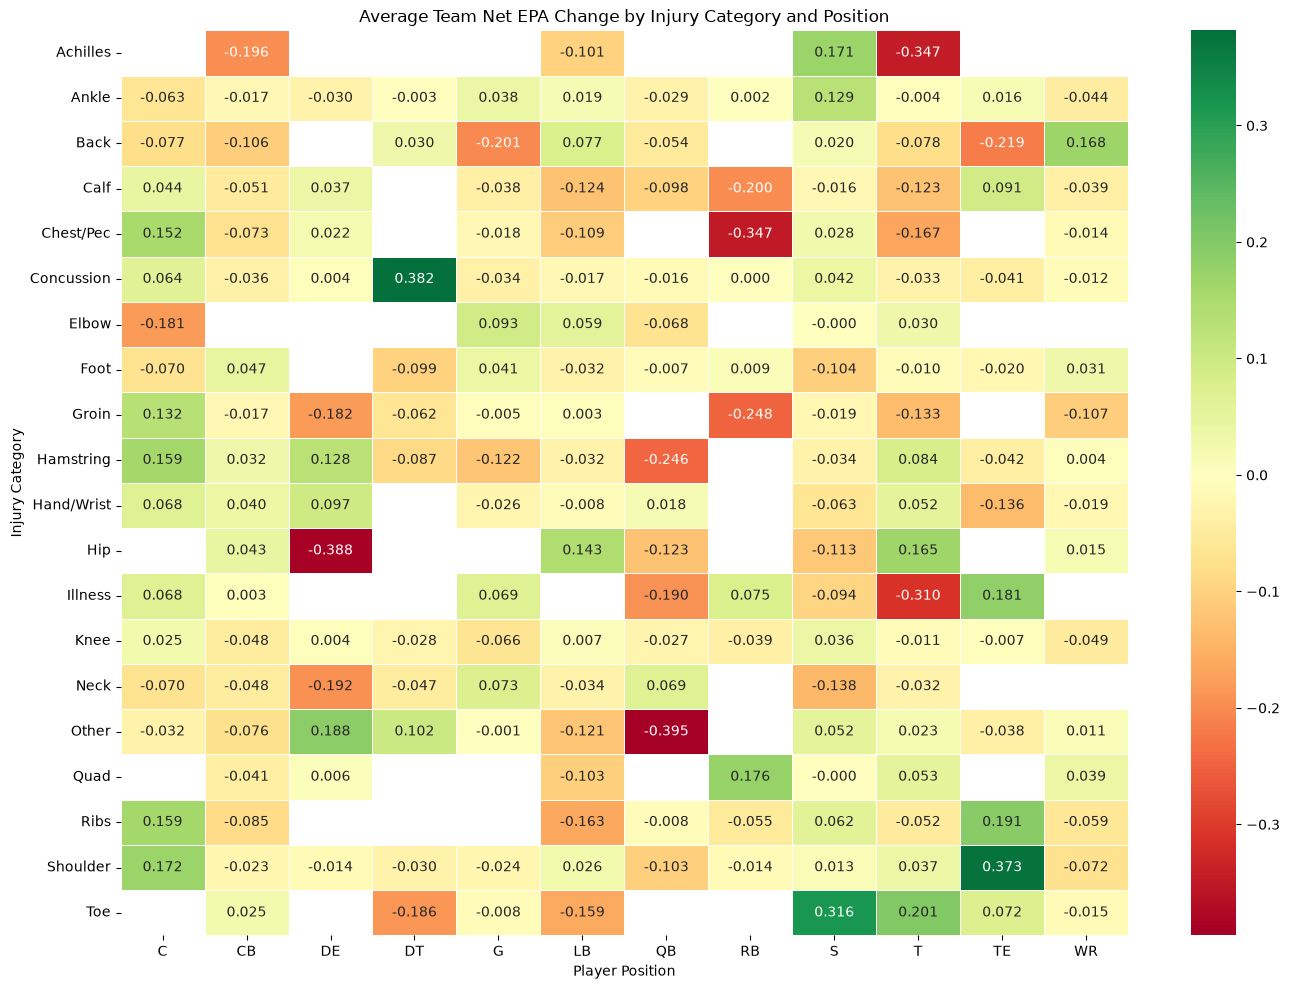

In [24]:
#Visualize 
heatmap_data = injury_performance.pivot_table(
    index="injury_category",
    columns="position",
    values="net_epa_change",
    aggfunc="mean"
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Average Team Net EPA Change by Injury Category and Position")
plt.xlabel("Player Position")
plt.ylabel("Injury Category")
plt.tight_layout()
plt.show()

Model 2: Decision Tree

In [25]:
# Define tree_data and target variable from combined_regression
tree_data = combined_regression[
    ["injury_category", "position", "previous_injury_count", "games_missed", "net_epa_change"]
].dropna().copy()
y_tree = tree_data["net_epa_change"]

# Prepare injury related predictors
X_tree = pd.get_dummies(
    tree_data[["injury_category", "position", "previous_injury_count", "games_missed"]],
    columns=["injury_category", "position"],
    dtype=int)

# Train the Decision Tree model
X_train, X_test, y_train, y_test = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42
)

tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

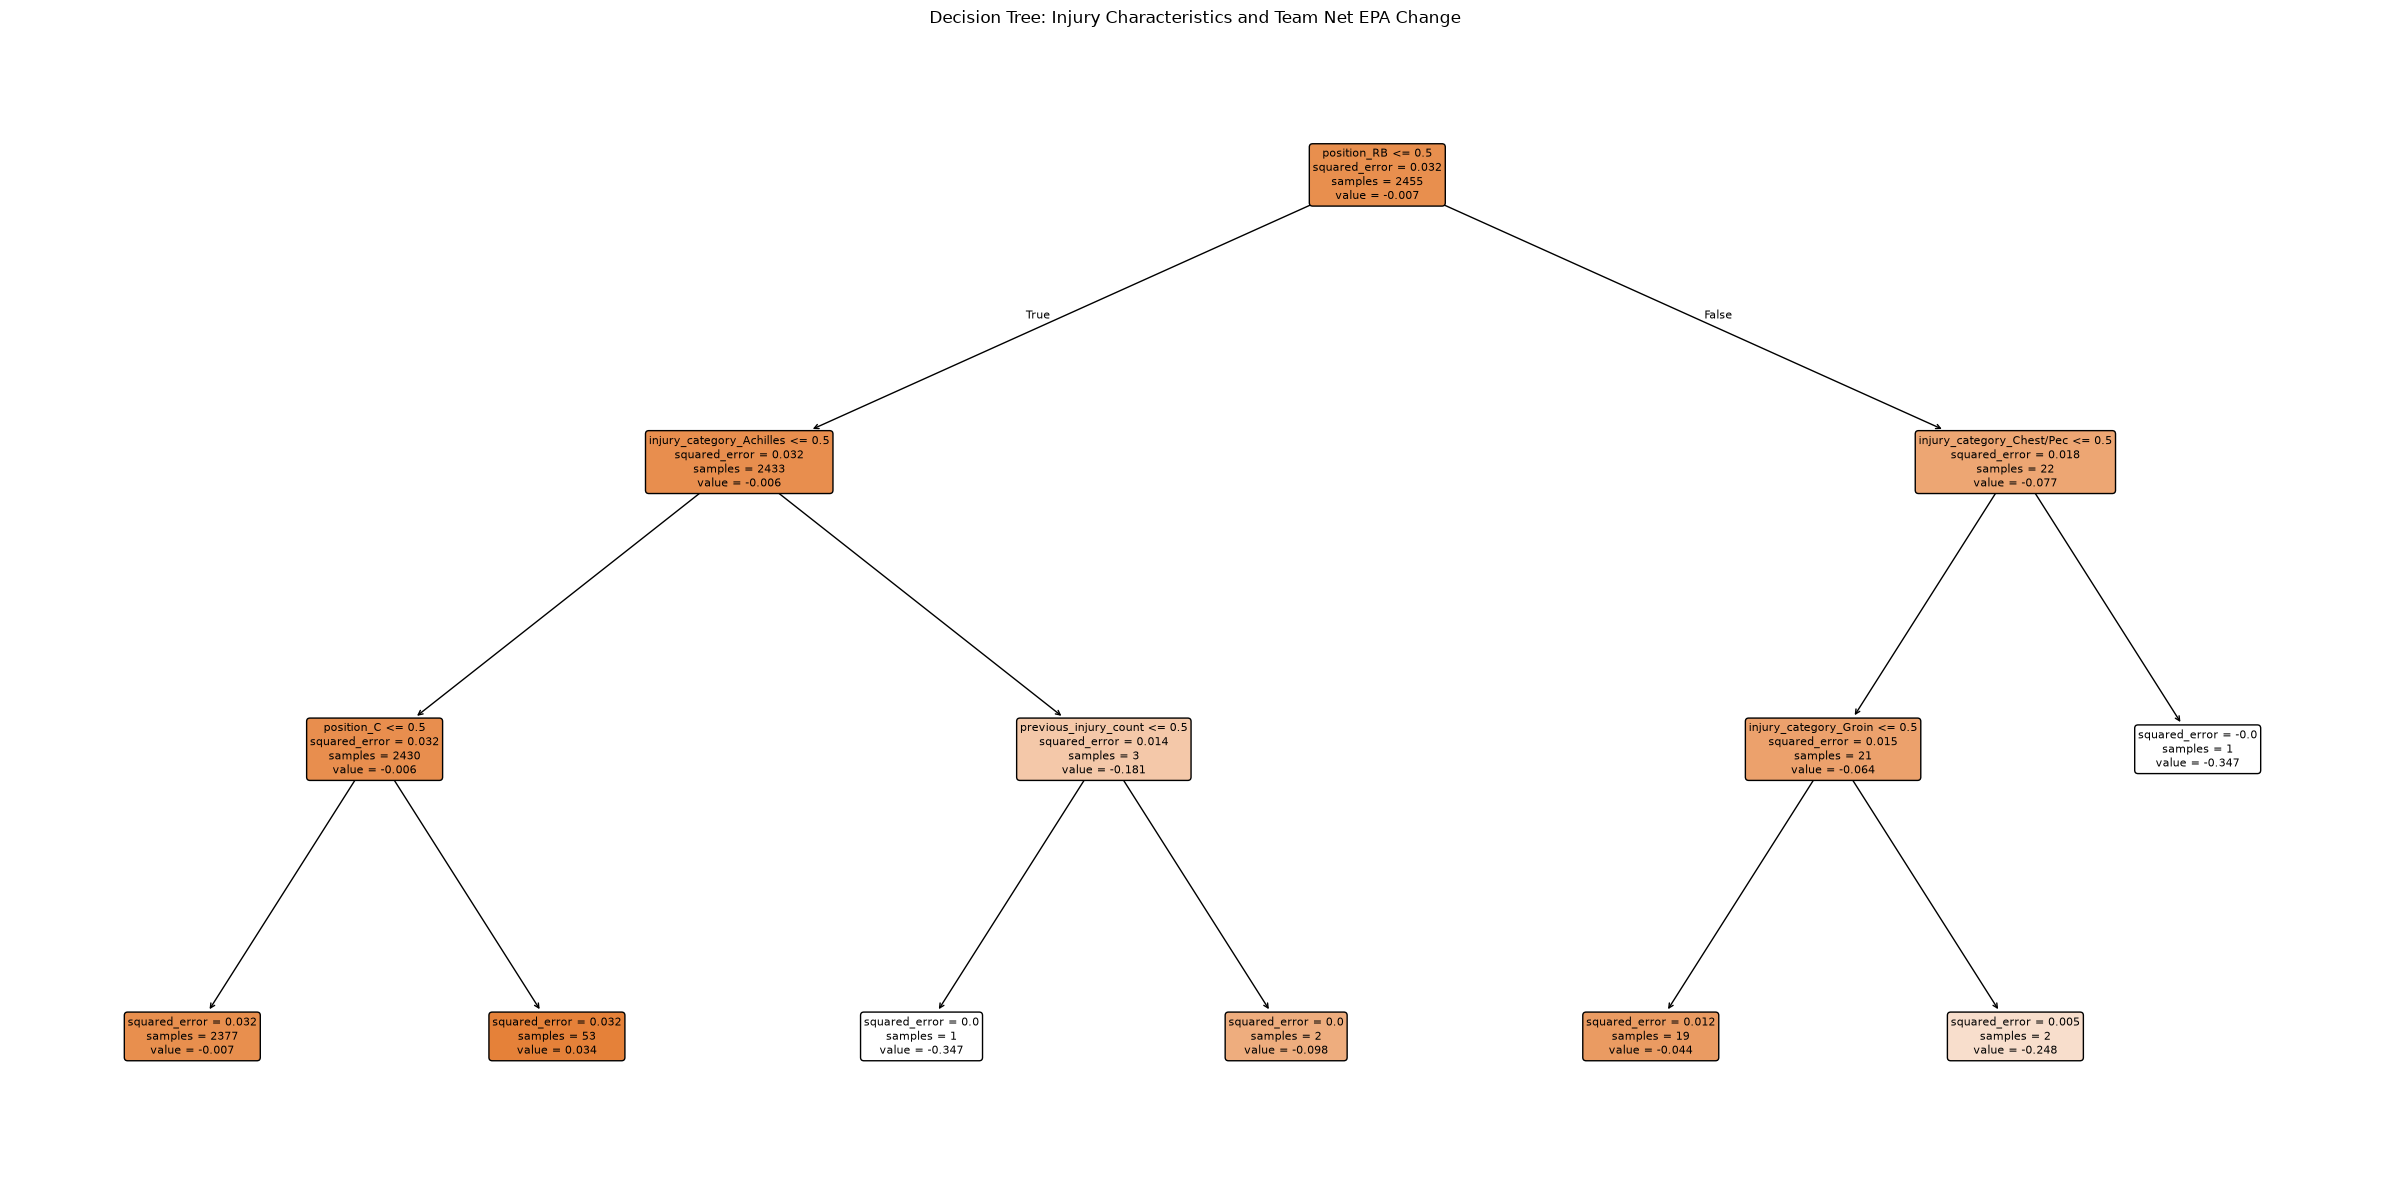

In [26]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=X_tree.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree: Injury Characteristics and Team Net EPA Change")
plt.tight_layout()
plt.show()

Model 3: Quantile Regression

In [55]:
df = combined_regression.dropna(subset=["injury_group"]).copy()
team_col = "team"

formula = f"""
net_epa_change ~ C({team_col})
+ C(injury_group, Treatment(reference="No Qualifying Player Out"))
+ C({team_col}):C(injury_group, Treatment(reference="No Qualifying Player Out"))
+ is_qb
+ net_epa_before
+ opp_strength_during
"""

quantiles = [0.25, 0.50, 0.75]
models = {q: smf.quantreg(formula, df).fit(q=q, max_iter=1000) for q in quantiles}

teams = sorted(df[team_col].dropna().unique())
team_dropdown = widgets.Dropdown(
    options=teams,
    value="LA" if "LA" in teams else teams[0],
    description="Select Team:",
    style={"description_width": "initial"},
)

injury_groups = ["Lower Body", "Upper Body", "Concussion", "Illness"]
control_means = {
    "is_qb": 0,
    "net_epa_before": df["net_epa_before"].mean(),
    "opp_strength_during": df["opp_strength_during"].mean(),
}

def plot_team_impact(selected_team):
    team_df = df[df[team_col] == selected_team]
    min_n = 8

    # Selected team's normal (median) healthy baseline
    healthy_row = pd.DataFrame([{
        team_col: selected_team,
        "injury_group": "No Qualifying Player Out",
        **control_means,
    }])
    healthy_median = models[0.50].predict(healthy_row).iloc[0]

    rows = []
    for ig in injury_groups:
        count = len(team_df[team_df["injury_group"] == ig])
        pred_row = pd.DataFrame([{
            team_col: selected_team,
            "injury_group": ig,
            **control_means,
        }])

        if count < min_n:
            # League-average injury outcomes relative to each team's healthy median
            diffs = {}
            for q in quantiles:
                team_diffs = []
                for t in teams:
                    r_inj = pred_row.copy()
                    r_inj[team_col] = t
                    r_hlth = healthy_row.copy()
                    r_hlth[team_col] = t
                    team_diffs.append(
                        models[q].predict(r_inj).iloc[0] - models[0.50].predict(r_hlth).iloc[0]
                    )
                diffs[q] = np.mean(team_diffs)
            label = f"{ig} (League Avg, n={count})"
        else:
            diffs = {
                q: models[q].predict(pred_row).iloc[0] - healthy_median
                for q in quantiles
            }
            label = f"{ig} (Team Specific, n={count})"

        rows.append({
            "Injury Group": label,
            "Q25": diffs[0.25],
            "Q50": diffs[0.50],
            "Q75": diffs[0.75],
        })

    plot_df = pd.DataFrame(rows).set_index("Injury Group")[::-1]

    fig, ax = plt.subplots(figsize=(10.5, 5.8))
    plot_df.plot(
        kind="barh",
        ax=ax,
        color=["#d95f02", "#7570b3", "#1b9e77"],
        width=0.72,
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1.2)
    ax.set_title(
        f"{selected_team}: Team Net EPA Impact by Injury Type (vs. Normal Healthy Baseline = 0.00)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("EPA Change vs. Team's Normal Healthy Game (Negative = Worse Than Normal)")
    ax.set_ylabel("")

    handles, _ = ax.get_legend_handles_labels()
    ax.legend(
        handles[:3],
        [
            "25th Percentile (Worst-Case Floor)",
            "50th Percentile (Typical Median)",
            "75th Percentile (Best-Case Ceiling)",
        ],
        loc="best",
    )
    plt.tight_layout()
    plt.show()

out = widgets.interactive_output(plot_team_impact, {"selected_team": team_dropdown})
display(team_dropdown, out)

Dropdown(description='Select Team:', index=16, options=('ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE'…

Output()